### Import Libraries

In [40]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from torch.utils.data import DataLoader

from torchvision import datasets
from torchvision import transforms

### Configure the Device

In [41]:
device = torch.device("cpu")
print("Device:",device)

Device: cpu


### Create the Image Transform

#### Convert the Images to Tensors

In [42]:
transform = transforms.ToTensor()

### Download CIFAR-10 Dataset

In [43]:
train_dataset = datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

Files already downloaded and verified
Files already downloaded and verified


### Create DataLoaders

In [44]:
train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False,
    num_workers=0
)

### Inspect the Dataset

In [45]:
print(
    "Training Samples:",
    len(train_dataset)
)

print(
    "Testing Samples:",
    len(test_dataset)
)

Training Samples: 50000
Testing Samples: 10000


### Inspect One Image

In [46]:
image, label = train_dataset[0]

print("Image shape:", image.shape)
print("Label:", label)

Image shape: torch.Size([3, 32, 32])
Label: 6


### Inspect a Batch

In [47]:
images, labels = next(
    iter(train_loader)
)

print(
    "Batch Images:",
    images.shape
)

print(
    "Batch Labels:",
    labels.shape
)

Batch Images: torch.Size([64, 3, 32, 32])
Batch Labels: torch.Size([64])


### Visualize an Image

Matplotlib expects [H, W, C]

While PyTorch uses:
[C, H, W]

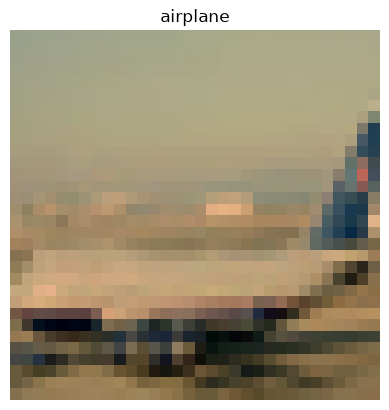

In [48]:
# we need to permute (convert those images)
image = images[0].permute(
    1, 2, 0
)

plt.imshow(image)

plt.title(
    train_dataset.classes[
        labels[0]
    ]
)

plt.axis("off")

plt.show()

### Build the CNN

Create the CNN workflow

In [49]:
class CIFAR10CNN(nn.Module):

    def __init__(self):

        super().__init__()

        self.features = nn.Sequential(

            nn.Conv2d(
                in_channels=3,
                out_channels=32,
                kernel_size=3,
                padding=1
            ),

            nn.ReLU(),

            nn.MaxPool2d(
                kernel_size=2
            ),

            nn.Conv2d(
                in_channels=32,
                out_channels=64,
                kernel_size=3,
                padding=1
            ),

            nn.ReLU(),

            nn.MaxPool2d(
                kernel_size=2
            )
        )

        self.classifier = nn.Sequential(

            nn.Flatten(),

            nn.Linear(
                64 * 8 * 8,
                128
            ),

            nn.ReLU(),

            nn.Dropout(0.3),

            nn.Linear(
                128,
                10
            )
        )

    def forward(self, x):

        x = self.features(x)

        x = self.classifier(x)

        return x

### Create the Model

In [50]:
model = CIFAR10CNN().to(device)
print(model)

CIFAR10CNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=4096, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)


### Loss Function

#### For Multiclass Classification

In [51]:
loss_fn = nn.CrossEntropyLoss()

#### For Binary Classification

In [52]:
nn.BCEWithLogitsLoss()

BCEWithLogitsLoss()

# Optimizer

In [53]:
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

## CNN Training Step

In [54]:
def train_step(
    model,
    dataloader,
    loss_fn,
    optimizer,
    device
):

    model.train()

    total_loss = 0.0
    correct = 0
    total = 0

    for X, y in dataloader:

        X = X.to(device)
        y = y.to(device)

        optimizer.zero_grad()

        logits = model(X)

        loss = loss_fn(
            logits,
            y
        )

        loss.backward()

        optimizer.step()

        total_loss += loss.item()

        predictions = logits.argmax(
            dim=1
        )

        correct += (
            predictions == y
        ).sum().item()

        total += y.size(0)

    average_loss = (
        total_loss /
        len(dataloader)
    )

    accuracy = correct / total

    return average_loss, accuracy

# CNN Validation Step

In [55]:
def validation_step(
    model,
    dataloader,
    loss_fn,
    device
):

    model.eval()

    total_loss = 0.0
    correct = 0
    total = 0


    with torch.no_grad():

        for X, y in dataloader:

            X = X.to(device)
            y = y.to(device)

            logits = model(X)

            loss = loss_fn(
                logits,
                y
            )

            total_loss += loss.item()

            predictions = logits.argmax(
                dim=1
            )

            correct += (
                predictions == y
            ).sum().item()

            total += y.size(0)

    average_loss = (
        total_loss / 
        len(dataloader)
    )

    accuracy = correct / total

    return average_loss, accuracy

# Training Loop

In [ ]:
# number of epochs for testing
epochs = 10 # can change this to any value. the higher the value, the longer the model trains.

history = {
    "train_loss": [],
    "train_accuracy": [],
    "test_loss": [],
    "test_accuracy": []
}

In [57]:
for epoch in range(epochs):

    train_loss, train_acc = train_step(
        model,
        train_loader,
        loss_fn,
        optimizer,
        device
    )

    test_loss, test_acc = validation_step(
        model,
        test_loader,
        loss_fn,
        device
    )

    history["train_loss"].append(
        train_loss
    )

    history["train_accuracy"].append(
        train_acc
    )

    history["test_loss"].append(
        test_loss
    )

    history["test_accuracy"].append(
        test_acc
    )

    print(
        f"Epoch {epoch + 1}/{epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Test Loss: {test_loss:.4f} | "
        f"Test Acc: {test_acc:.4f}"
    )

Epoch 1/10 | Train Loss: 1.5708 | Train Acc: 0.4243 | Test Loss: 1.2631 | Test Acc: 0.5464
Epoch 2/10 | Train Loss: 1.2520 | Train Acc: 0.5493 | Test Loss: 1.1275 | Test Acc: 0.5928
Epoch 3/10 | Train Loss: 1.0930 | Train Acc: 0.6128 | Test Loss: 0.9946 | Test Acc: 0.6481
Epoch 4/10 | Train Loss: 0.9999 | Train Acc: 0.6473 | Test Loss: 0.9366 | Test Acc: 0.6704
Epoch 5/10 | Train Loss: 0.9253 | Train Acc: 0.6740 | Test Loss: 0.9428 | Test Acc: 0.6712
Epoch 6/10 | Train Loss: 0.8735 | Train Acc: 0.6905 | Test Loss: 0.8768 | Test Acc: 0.6941
Epoch 7/10 | Train Loss: 0.8178 | Train Acc: 0.7119 | Test Loss: 0.8723 | Test Acc: 0.6960
Epoch 8/10 | Train Loss: 0.7759 | Train Acc: 0.7247 | Test Loss: 0.8556 | Test Acc: 0.7054
Epoch 9/10 | Train Loss: 0.7377 | Train Acc: 0.7351 | Test Loss: 0.8331 | Test Acc: 0.7132
Epoch 10/10 | Train Loss: 0.7010 | Train Acc: 0.7498 | Test Loss: 0.8640 | Test Acc: 0.7043


# Training Loss

### Loss

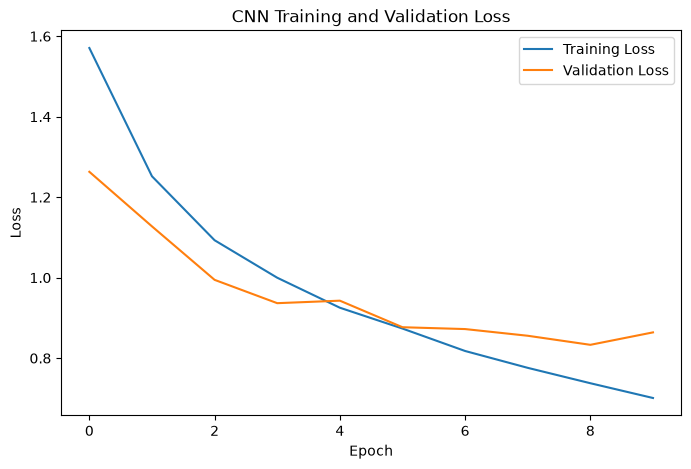

In [58]:
plt.figure(figsize=(8,5))

plt.plot(
    history["train_loss"],
    label="Training Loss"
)

plt.plot(
    history["test_loss"],
    label="Validation Loss"
)


plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title(
    "CNN Training and Validation Loss"
)

plt.legend()
plt.show()

### Accuracy

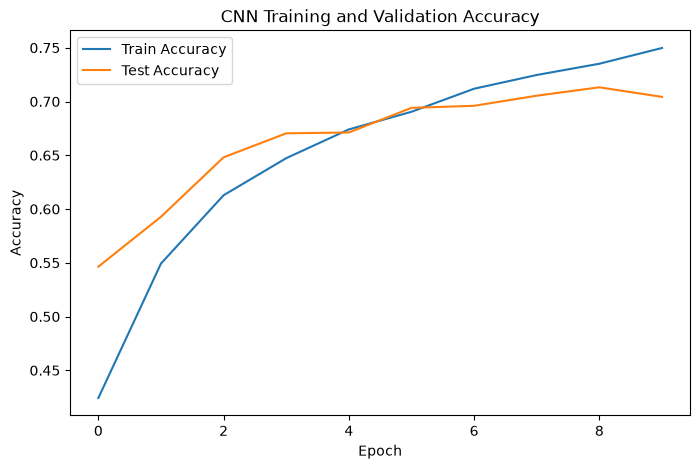

In [62]:
plt.figure(figsize=(8,5))

plt.plot(
    history["train_accuracy"],
    label="Train Accuracy"
)

plt.plot(
    history["test_accuracy"],
    label="Test Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.title(
    "CNN Training and Validation Accuracy"
)
plt.legend()
plt.show()

### CNN Prediction

#### Prediction on one Image

In [65]:
model.eval()

image, label = test_dataset[0]

image_batch = image.unsqueeze(0)

# unsqueeze(0) => Individual Image has [3, 32, 32], but CNN expects [Batch, Channels, Height, Width].
# so, unsqueeze(0) turns [3, 32, 32] into [1, 3, 32, 32]. Where 1 means batch_size

with torch.no_grad():

    logits = model(
        image_batch.to(device)
    )

prediction = logits.argmax(
    dim=1
).item()

In [66]:
print(
    "Actual:",
    test_dataset.classes[label]
)

print(
    "Predicted:",
    test_dataset.classes[prediction]
)

Actual: cat
Predicted: cat


## Get class Probabilities

In [68]:
# for multiclass, we use;
probabilities = torch.softmax(
    logits,
    dim=1
)

# print probabilities
print(probabilities)

tensor([[1.0757e-03, 2.4278e-04, 1.7163e-04, 9.4706e-01, 2.5699e-05, 3.9098e-02,
         8.6298e-04, 2.0855e-05, 1.1205e-02, 2.3514e-04]])


## Top Predictions

In [71]:
predicted_probability = (
    probabilities[0, prediction]
    .item()
)

print(
    "Confidence:",
    predicted_probability
)

Confidence: 0.9470621943473816


## Visualize Prediction

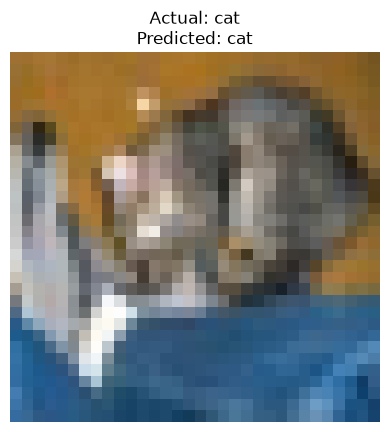

In [74]:
plt.imshow(
    image.permute(1, 2, 0)
)

plt.title(
    f"Actual: "
    f"{test_dataset.classes[label]}\n"
    f"Predicted: "
    f"{test_dataset.classes[prediction]}"
)

plt.axis("off")

plt.show()

#### Save the CNN

In [75]:
torch.save(
    model.state_dict(),
    "cifar10_cnn.pth"
)

#### To Load the CNN

In [76]:
model.load_state_dict(
    torch.load(
        "cifar10_cnn.pth",
        map_location=device,
        weights_only=True
    )
)

<All keys matched successfully>

### Complete CNN Architecture

             CIFAR-10 IMAGE
               3×32×32
                  │
                  ↓
             Conv2D 3→32 nn.Conv2d()  - Convolution
                  │
                  ↓
                ReLU  nn.ReLU() - Activation
                  │
                  ↓
              MaxPool. nn.MaxPool2d() - Downsampling()
               16×16
                  │
                  ↓
             Conv2D 32→64
                  │
                  ↓
                ReLU
                  │
                  ↓
              MaxPool
                8×8
                  │
                  ↓
             64×8×8
                  │
                  ↓
               Flatten. nn.Flatten()  - Converts feature maps into a vector.
                  │
                  ↓
                4096
                  │
                  ↓
               Linear  nn.Linear() - Classification/regression layers.
                  │
                  ↓
                 128
                  │
                  ↓
                ReLU
                  │
                  ↓
               Dropout. nn.dropout() - regularization.
                  │
                  ↓
                Linear
                  │
                  ↓
                 10
                  │
                  ↓
              CLASS LOGITS

CNN Tensor Transformation

One of the most important things to master is shape tracking.

Our network:

Input
[3, 32, 32]

      ↓ Conv2d

[32, 32, 32]

      ↓ MaxPool2d

[32, 16, 16]

      ↓ Conv2d

[64, 16, 16]

      ↓ MaxPool2d

[64, 8, 8]

      ↓ Flatten

[4096]

      ↓ Linear

[128]

      ↓ Linear

[10]

A Useful Debugging Technique

When developing CNNs, print tensor shapes.

For example:

In [79]:
def forward(self, x):

    print("Input:", x.shape)

    x = self.features(x)

    print("Features:", x.shape)

    x = self.classifier(x)

    print("Output:", x.shape)

    return x